## 🏦️ Loan Risk Prediction

Given *data about German loans*, let's try to detect **high-risk loans** in the data.

We will use a logistic regression model to make our predictions.

Data source: https://www.kaggle.com/datasets/kabure/german-credit-data-with-risk

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = pd.read_csv('archive/german_credit_data.csv')
data

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...,...
995,995,31,female,1,own,little,NaN,1736,12,furniture/equipment,good
996,996,40,male,3,own,little,little,3857,30,car,good
997,997,38,male,2,own,little,NaN,804,12,radio/TV,good
998,998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
 10  Risk              1000 non-null   object
dtypes: int64(5), object(6)
memory usage: 86.1+ KB


### Preprocessing

In [4]:
df = data.copy()

In [5]:
df

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...,...
995,995,31,female,1,own,little,NaN,1736,12,furniture/equipment,good
996,996,40,male,3,own,little,little,3857,30,car,good
997,997,38,male,2,own,little,NaN,804,12,radio/TV,good
998,998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [6]:
# Drop duplicate id column
df = df.drop('Unnamed: 0', axis=1)

In [7]:
df.isna().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [8]:
df['Saving accounts'].unique()

array([nan, 'little', 'quite rich', 'rich', 'moderate'], dtype=object)

In [9]:
df['Checking account'].unique()

array(['little', 'moderate', nan, 'rich'], dtype=object)

In [10]:
# Encode missing values as 'none'
for column in ['Saving accounts', 'Checking account']:
    df[column] = df[column].fillna('none')

In [11]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,none,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,none,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,none,1736,12,furniture/equipment,good
996,40,male,3,own,little,little,3857,30,car,good
997,38,male,2,own,little,none,804,12,radio/TV,good
998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [12]:
df.isna().sum()

Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64

In [13]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,none,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,none,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,none,1736,12,furniture/equipment,good
996,40,male,3,own,little,little,3857,30,car,good
997,38,male,2,own,little,none,804,12,radio/TV,good
998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [16]:
{column: list(df[column].unique()) for column in df.select_dtypes('object').columns}

{'Sex': ['male', 'female'],
 'Housing': ['own', 'free', 'rent'],
 'Saving accounts': ['none', 'little', 'quite rich', 'rich', 'moderate'],
 'Checking account': ['little', 'moderate', 'none', 'rich'],
 'Purpose': ['radio/TV',
  'education',
  'furniture/equipment',
  'car',
  'business',
  'domestic appliances',
  'repairs',
  'vacation/others'],
 'Risk': ['good', 'bad']}

In [17]:
{column: len(df[column].unique()) for column in df.select_dtypes('object').columns}

{'Sex': 2,
 'Housing': 3,
 'Saving accounts': 5,
 'Checking account': 4,
 'Purpose': 8,
 'Risk': 2}

In [18]:
def binary_encode(df, columns_with_positive_values):
    df = df.copy()
    for column, positive_value in columns_with_positive_values:
        df[column] = df[column].apply(lambda x: 1 if x == positive_value else 0)
    return df

In [19]:
df['Risk'].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [20]:
# Binary encode the Sex and Risk columns
df = binary_encode(
    df,
    columns_with_positive_values=[
        ('Sex', 'male'),
        ('Risk', 'bad')
    ]
)

In [21]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,1,2,own,none,little,1169,6,radio/TV,0
1,22,0,2,own,little,moderate,5951,48,radio/TV,1
2,49,1,1,own,little,none,2096,12,education,0
3,45,1,2,free,little,little,7882,42,furniture/equipment,0
4,53,1,2,free,little,little,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...
995,31,0,1,own,little,none,1736,12,furniture/equipment,0
996,40,1,3,own,little,little,3857,30,car,0
997,38,1,2,own,little,none,804,12,radio/TV,0
998,23,1,2,free,little,little,1845,45,radio/TV,1


In [22]:
{column: list(df[column].unique()) for column in df.select_dtypes('object').columns}

{'Housing': ['own', 'free', 'rent'],
 'Saving accounts': ['none', 'little', 'quite rich', 'rich', 'moderate'],
 'Checking account': ['little', 'moderate', 'none', 'rich'],
 'Purpose': ['radio/TV',
  'education',
  'furniture/equipment',
  'car',
  'business',
  'domestic appliances',
  'repairs',
  'vacation/others']}

In [25]:
# Ordinal encode the Saving accounts and Checking account columns
def ordinal_encode(df, columns_with_orderings):
    df = df.copy()
    for column, ordering in columns_with_orderings:
        df[column] = df[column].apply(lambda x: ordering.index(x))
    return df

df = ordinal_encode(
    df,
    columns_with_orderings=[
        ('Saving accounts', ['none', 'little', 'moderate', 'rich', 'quite rich']),
        ('Checking account', ['none', 'little', 'moderate', 'rich'])
    ]
)

In [26]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,1,2,own,0,1,1169,6,radio/TV,0
1,22,0,2,own,1,2,5951,48,radio/TV,1
2,49,1,1,own,1,0,2096,12,education,0
3,45,1,2,free,1,1,7882,42,furniture/equipment,0
4,53,1,2,free,1,1,4870,24,car,1
...,...,...,...,...,...,...,...,...,...,...
995,31,0,1,own,1,0,1736,12,furniture/equipment,0
996,40,1,3,own,1,1,3857,30,car,0
997,38,1,2,own,1,0,804,12,radio/TV,0
998,23,1,2,free,1,1,1845,45,radio/TV,1


In [27]:
{column: list(df[column].unique()) for column in df.select_dtypes('object').columns}

{'Housing': ['own', 'free', 'rent'],
 'Purpose': ['radio/TV',
  'education',
  'furniture/equipment',
  'car',
  'business',
  'domestic appliances',
  'repairs',
  'vacation/others']}

In [28]:
def onehot_encode(df, columns_with_prefixes):
    df = df.copy()
    for column, prefix in columns_with_prefixes:
        dummies = pd.get_dummies(df[column], prefix=prefix, dtype=int)
        df = pd.concat([df, dummies], axis=1)
        df = df.drop(column, axis=1)
    return df

In [29]:
# One-hot encode the Housing and Purpose columns
df = onehot_encode(
    df,
    columns_with_prefixes = [
        ('Housing', 'H'),
        ('Purpose', 'P')
    ]
)

In [30]:
df

,Age,Sex,Job,Saving accounts,Checking account,Credit amount,Duration,Risk,H_free,H_own,H_rent,P_business,P_car,P_domestic appliances,P_education,P_furniture/equipment,P_radio/TV,P_repairs,P_vacation/others
0,67,1,2,0,1,1169,6,0,0,1,0,0,0,0,0,0,1,0,0
1,22,0,2,1,2,5951,48,1,0,1,0,0,0,0,0,0,1,0,0
2,49,1,1,1,0,2096,12,0,0,1,0,0,0,0,1,0,0,0,0
3,45,1,2,1,1,7882,42,0,1,0,0,0,0,0,0,1,0,0,0
4,53,1,2,1,1,4870,24,1,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31,0,1,1,0,1736,12,0,0,1,0,0,0,0,0,1,0,0,0
996,40,1,3,1,1,3857,30,0,0,1,0,0,1,0,0,0,0,0,0
997,38,1,2,1,0,804,12,0,0,1,0,0,0,0,0,0,1,0,0
998,23,1,2,1,1,1845,45,1,1,0,0,0,0,0,0,0,1,0,0


### Splitting and Scaling

In [31]:
# Split df into X and y
y = df['Risk'].copy()
X = df.drop('Risk', axis=1).copy()

In [32]:
y

0      0
1      1
2      0
3      0
4      1
      ..
995    0
996    0
997    0
998    1
999    0
Name: Risk, Length: 1000, dtype: int64

In [33]:
X

,Age,Sex,Job,Saving accounts,Checking account,Credit amount,Duration,H_free,H_own,H_rent,P_business,P_car,P_domestic appliances,P_education,P_furniture/equipment,P_radio/TV,P_repairs,P_vacation/others
0,67,1,2,0,1,1169,6,0,1,0,0,0,0,0,0,1,0,0
1,22,0,2,1,2,5951,48,0,1,0,0,0,0,0,0,1,0,0
2,49,1,1,1,0,2096,12,0,1,0,0,0,0,1,0,0,0,0
3,45,1,2,1,1,7882,42,1,0,0,0,0,0,0,1,0,0,0
4,53,1,2,1,1,4870,24,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31,0,1,1,0,1736,12,0,1,0,0,0,0,0,1,0,0,0
996,40,1,3,1,1,3857,30,0,1,0,0,1,0,0,0,0,0,0
997,38,1,2,1,0,804,12,0,1,0,0,0,0,0,0,1,0,0
998,23,1,2,1,1,1845,45,1,0,0,0,0,0,0,0,1,0,0


In [34]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

In [35]:
X_train

,Age,Sex,Job,Saving accounts,Checking account,Credit amount,Duration,H_free,H_own,H_rent,P_business,P_car,P_domestic appliances,P_education,P_furniture/equipment,P_radio/TV,P_repairs,P_vacation/others
541,60,1,2,1,0,2032,24,1,0,0,0,1,0,0,0,0,0,0
440,39,1,3,1,0,1884,12,0,1,0,0,1,0,0,0,0,0,0
482,57,0,2,3,1,3622,30,0,0,1,0,0,0,0,1,0,0,0
422,47,1,1,1,2,958,12,0,1,0,0,1,0,0,0,0,0,0
778,38,1,3,3,0,5711,36,0,1,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,39,1,3,1,0,6458,18,0,1,0,0,1,0,0,0,0,0,0
270,32,1,2,0,0,2662,18,0,1,0,0,1,0,0,0,0,0,0
860,27,1,2,3,0,5804,24,0,1,0,0,1,0,0,0,0,0,0
435,25,1,2,0,2,1484,12,0,1,0,0,0,0,0,0,1,0,0


In [36]:
# Scale X
scaler = StandardScaler()
scaler.fit(X_train)

X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [37]:
X_train

,Age,Sex,Job,Saving accounts,Checking account,Credit amount,Duration,H_free,H_own,H_rent,P_business,P_car,P_domestic appliances,P_education,P_furniture/equipment,P_radio/TV,P_repairs,P_vacation/others
541,2.179382,0.681495,0.095819,-0.214098,-1.054313,-0.462936,0.231016,2.865402,-1.592279,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
440,0.311885,0.681495,1.620212,-0.214098,-1.054313,-0.512772,-0.778104,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
482,1.912597,-1.467363,0.095819,1.744968,-0.014849,0.072458,0.735576,-0.348991,-1.592279,2.176627,-0.319941,-0.726900,-0.120386,-0.236235,2.232242,-0.636885,-0.157766,-0.120386
422,1.023312,0.681495,-1.428574,-0.214098,1.024614,-0.824580,-0.778104,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
778,0.222956,0.681495,1.620212,1.744968,-1.054313,0.775879,1.240136,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,0.311885,0.681495,1.620212,-0.214098,-1.054313,1.027413,-0.273544,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
270,-0.310614,0.681495,0.095819,-1.193631,-1.054313,-0.250799,-0.273544,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
860,-0.755257,0.681495,0.095819,1.744968,-1.054313,0.807194,0.231016,-0.348991,0.628031,-0.459426,-0.319941,1.375704,-0.120386,-0.236235,-0.447980,-0.636885,-0.157766,-0.120386
435,-0.933113,0.681495,0.095819,-1.193631,1.024614,-0.647462,-0.778104,-0.348991,0.628031,-0.459426,-0.319941,-0.726900,-0.120386,-0.236235,-0.447980,1.570142,-0.157766,-0.120386


In [38]:
X_train.mean()

Age                      2.220446e-16
Sex                      2.791418e-17
Job                      1.344956e-16
Saving accounts         -5.582836e-17
Checking account         5.329071e-17
Credit amount           -3.806479e-17
Duration                 1.015061e-16
H_free                   4.821540e-17
H_own                   -1.103879e-16
H_rent                   0.000000e+00
P_business              -2.537653e-18
P_car                    7.612958e-17
P_domestic appliances    2.918301e-17
P_education             -4.567775e-17
P_furniture/equipment    2.537653e-17
P_radio/TV              -5.582836e-17
P_repairs                5.075305e-18
P_vacation/others        3.552714e-17
dtype: float64

In [39]:
X_train.var()

Age                      1.001431
Sex                      1.001431
Job                      1.001431
Saving accounts          1.001431
Checking account         1.001431
Credit amount            1.001431
Duration                 1.001431
H_free                   1.001431
H_own                    1.001431
H_rent                   1.001431
P_business               1.001431
P_car                    1.001431
P_domestic appliances    1.001431
P_education              1.001431
P_furniture/equipment    1.001431
P_radio/TV               1.001431
P_repairs                1.001431
P_vacation/others        1.001431
dtype: float64

### Training

In [40]:
y_train.value_counts()

Risk
0    491
1    209
Name: count, dtype: int64

In [101]:
model = LogisticRegression(
    class_weight = {
        0: 1,
        1: 2
    }
)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,"{0: 1, 1: 2}"
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [102]:
model.score(X_test, y_test)

0.6433333333333333

In [103]:
model.predict(X_test)

array([0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1])

In [104]:
list(map(lambda x: x[1], (model.predict_proba(X_test) >= 0.5).astype(int)))

[np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.in

### Results

In [105]:
def evaluate_model(model, X_test, y_test, classification_threshold = 0.5):
    y_true = np.array(y_test)
    
    y_pred = (model.predict_proba(X_test) >= classification_threshold).astype(int)
    y_pred = list(map(lambda x: x[1], y_pred))

    print("Test Accuracy: {:.2f}%".format(accuracy_score(y_true, y_pred) * 100))

    cm = confusion_matrix(y_true, y_pred)

    clr = classification_report(y_true, y_pred, target_names=['Not Risky', 'Risky'])

    plt.figure(figsize=(5,5))
    sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=False, cmap='Blues')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.xticks(np.arange(2) + 0.5, ['Not Risky', 'Risky'])
    plt.yticks(np.arange(2) + 0.5, ['Not Risky', 'Risky'])
    plt.show()

    print("Classification Report:\n---------------------------- \n", clr)

Test Accuracy: 64.33%


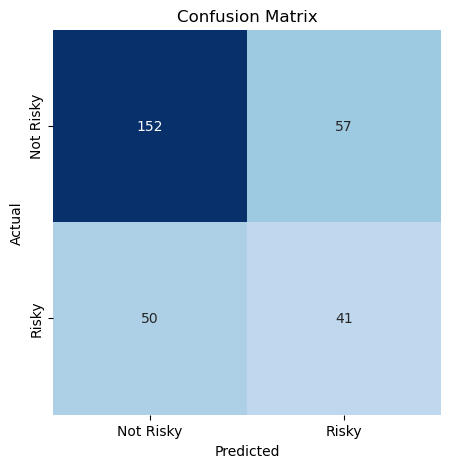

Classification Report:
---------------------------- 
               precision    recall  f1-score   support

   Not Risky       0.75      0.73      0.74       209
       Risky       0.42      0.45      0.43        91

    accuracy                           0.64       300
   macro avg       0.59      0.59      0.59       300
weighted avg       0.65      0.64      0.65       300



In [106]:
evaluate_model(model, X_test, y_test, classification_threshold=0.5)